# Ranking województw ze względu na potencjał rolnictwa

Przedmiotem niniejszego projektu jest ocena i przestrzenna klasyfikacja polskich województw pod kątem ich potencjału rolniczego. Temat oraz metodyka badania zostały zainspirowane publikacją pt. „Ranking województw ze względu na potencjał rolnictwa” (J. Kisielińska, 2017).

Zgodnie z informacjami przedstawionymi w ww. publikacji, potencjał rolniczy jest zjawiskiem złożonym, charakteryzującym się silnym zróżnicowaniem regionalnym w skali kraju. Z punktu widzenia analizy danych, niemożliwe jest wyrażenie go za pomocą pojedynczego wskaźnika, z czego wynika potrzeba stosowania analizy wielowymiarowej.

Głównym celem projektu jest pomiar potencjału rolniczego poszczególnych województw w oparciu o aktualne dane statystyczne (z roku 2023) oraz zestawienie nowo powstałego układu z wynikami historycznymi przedstawionymi w publikacji.

## Wybór zmiennych diagnostycznych

Do analizy wybrano zestaw ośmiu zmiennych diagnostycznych wykorzystanych w publikacji referencyjnej. Są to:
   - $x_1$: udział użytków rolnych w powierzchni województwa
   - $x_2$: udział gruntów ugorowanych
   - $x_3$: udział zmeliorowanych użytków rolnych
   - $x_4$: pracujący w rolnictwie na 100 ha użytków rolnych
   - $x_5$: nakłady inwestycyjne w rolnictwie i łowiectwie na 100 ha użytków rolnych w tys. zł
   - $x_6$: wartość brutto środków trwałych w rolnictwie i łowiectwie na 100 ha użytków rolnych w tys. zł
   - $x_7$: zużycie nawozów mineralnych lub chemicznych na 1 ha użytków rolnych w kg
   - $x_8$: globalna produkcja rolnicza na 1 ha użytków rolnych w tys. zł

Zmienne dobrano pod kątem oceny skuteczności i potencjalnych możliwości prowadzenia produkcji rolniczej, a nie wyłącznie jej wielkości. Aby wyeliminować wpływ fizycznej wielkości poszczególnych województw na wyniki rankingu, wartości zmiennych zostały celowo uniezależnione od rozmiarów województw.

Dane zostały zaczerpnięte z "Rocznika Statystycznego Rolnictwa 2025" [GUS 2026] oraz przeliczone na jednostki z publikacji.

Zmienne $x_1, x_3, x_5, x_6, x_7, x_8$ uznano za stymulanty, a zmienne  $x_2, x_4$ za destymulanty.

In [1]:
import eda
import pandas as pd

df = pd.read_csv("data.csv", sep=";", decimal=",")

stimulants = ["x1", "x3", "x5", "x6", "x7", "x8"]
destimulants = ["x2", "x4"]
all_vars = ["x1", "x2", "x3", "x4", "x5", "x6", "x7", "x8"]

parameters_2014 = pd.DataFrame(
    {
        "x1": [0.49, 0.48, 0.20, 0.63, 0.33, 0.30],
        "x2": [0.035, 0.031, 0.472, 0.073, 0.018, 0.055],
        "x3": [0.44, 0.45, 0.25, 0.62, 0.23, 0.39],
        "x4": [18, 12, 0.73, 50, 5, 45],
        "x5": [3.8, 3.3, 0.50, 8.9, 1.6, 7.3],
        "x6": [78, 75, 0.22, 119, 55, 64],
        "x7": [1291, 1305, 0.24, 1880, 801, 1078],
        "x8": [5.8, 6.3, 0.23, 7.9, 2.9, 5.0],
    },
    index=["Średnia", "Mediana", "Wsp. zmienności", "Max", "Min", "Rozstęp"],
)

skumulowany_CPI_2007_14 = 1.2378
skumulowany_CPI_2014_23 = 1.4463

import seaborn as sns

sns.set_theme(style="white")
sns.set_palette("Set2")

## Wstępna analiza danych

W celu pomiaru potencjału rolniczego poszczególnych województw, konieczne jest przeprowadzenie wstępnej analizy dnaych, która przybliży zbiór danych poprzez:
- przejrzenie surowego zbioru danych
- manipulacja zmiennymi (ceny stałe)
- wyznaczenie podstawowych statystyk opisowych wszystkich zmiennych
- porównanie ich ze statystykami dla wartosci zmiennych z 2014 roku
- pokazanie rozkładów i znalezienie ewentualnych wartości odstających
- wyznaczenie korelacji pomiędzy zmiennymi

### Przegląd surowych danych

In [2]:
df

,Województwo,x1,x2,x3,x4,x5,x6,x7,x8
0,Dolnośląskie,45.46,0.6,55.2,4.68,58.38,991.17,139.4,10.72
1,Kujawsko-pomorskie,57.81,0.4,47.8,6.04,36.46,1030.83,169.6,14.85
2,Lubelskie,55.06,0.8,39.4,10.12,34.57,1084.18,139.4,10.64
3,Lubuskie,30.87,1.6,49.6,3.59,31.79,808.75,69.8,7.65
4,Łódzkie,53.50,1.0,44.1,8.96,35.33,1282.24,129.7,12.62
5,Małopolskie,35.64,0.8,29.3,26.22,51.08,1556.36,88.6,9.84
6,Mazowieckie,55.53,1.0,41.5,8.21,45.52,1310.71,101.6,13.38
7,Opolskie,54.17,0.4,69.4,5.52,64.72,1300.22,197.2,13.76
8,Podkarpackie,31.16,1.5,32.8,15.19,30.24,1190.09,94.7,6.95
9,Podlaskie,53.87,0.5,42.0,7.06,44.91,1140.17,99.6,12.94


Zmienne $x_1$, $x_2$, $x_3$ to udział procentowy - w publikacji zostały opisane w postaci ułamków dziesiętnych, więc dla celów porównawczych muszą zostać ujednolicone.

Przyglądając się wartościom zmiennych można zauważyć potencjalne występowanie wartości odstających w zmiennej $x_4$ dla województwa Małopolskiego czy zmiennej $x_6$ dla województwa Śląskiego - zostanie to poddane weryfikacji w dalszej części analizy.

### Przeliczenie parametrów zmiennych przez ceny stałe

In [3]:
parameters_2014.loc[["Średnia", "Mediana", "Max", "Min", "Rozstęp"], ["x5", "x6", "x8"]] *= skumulowany_CPI_2007_14
parameters_2014.loc[["Średnia", "Mediana", "Max", "Min", "Rozstęp"], ["x1", "x2", "x3"]] *= 100
parameters_2014 = parameters_2014.round(2)

parameters_2023 = eda.stats(df)

parameters_2023.loc[["Średnia", "Mediana", "Max", "Min", "Rozstęp"], ["x5", "x6", "x8"]] /= skumulowany_CPI_2014_23
parameters_2023 = parameters_2023.round(2)

W publikacji autorka przelicza zmienne cenowe na ceny stałe z wcześniejszego roku, z którym porównuje swoje obecne dane. Wykorzystuje do tego skumulowany wskaźnik cen (CPI):
$$
CPI_{t/t_0} = \prod_{k=t_0+1}^{t} \left(1 + \frac{\pi_k}{100}\right)
$$
gdzie $t_0$ to rok wcześniejszy, $t$ to rok późniejszy, a $\pi_k$ to stopa inflacji w roku $k$ (w %).

Aby przeliczyć wartości z roku $t$ na ceny roku $t_0$, dzieli się je przez $CPI_{t/t_0}$. Przeliczenie z cen roku $t_0$ na ceny roku $t$ wymaga mnożenia przez $CPI_{t/t_0}$.

W analizie przyjęto ceny z 2014 roku jako ceny bazowe. Statystyki z publikacji (w cenach z 2006 r.) pomnożono przez $CPI_{2014/2006} = 1{,}2378$, a statystyki dla 2023 roku, uprzednio wyliczone, podzielono przez $CPI_{2023/2014} = 1{,}4463$.

In [4]:
porownanie = eda.df_compare(parameters_2014, parameters_2023, title1="2014", title2="2023")
porownanie

x1    x2     x3     x4     x5       x6       x7  \
2014 Średnia          49.00  3.50  44.00  18.00   4.70    96.55  1291.00   
     Mediana          48.00  3.10  45.00  12.00   4.08    92.84  1305.00   
     Wsp. zmienności   0.20  0.47   0.25   0.73   0.50     0.22     0.24   
     Max              63.00  7.30  62.00  50.00  11.02   147.30  1880.00   
     Min              33.00  1.80  23.00   5.00   1.98    68.08   801.00   
     Rozstęp          30.00  5.50  39.00  45.00   9.04    79.22  1078.00   
2023 Średnia          45.28  0.94  47.74   8.58  29.88   817.11   120.02   
     Mediana          44.36  0.90  47.00   6.98  26.79   805.59   108.50   
     Wsp. zmienności   0.22  0.49   0.22   0.65   0.26     0.21     0.27   
     Max              59.09  1.80  69.40  26.22  45.32  1203.07   197.20   
     Min              30.08  0.40  29.30   2.94  19.81   559.19    69.80   
     Rozstęp          29.01  1.40  40.10  23.28  25.51   643.88   127.40   

                         x8  
2014 Średnia           7.18  
     Mediana           7.80  
     Wsp. zmienności   0.23  
     Max               9.78  
     Min               3.59  
     Rozstęp           6.19  
2023 Średnia           7.73  
     Mediana           7.38  
     Wsp. zmienności   0.25  
     Max              12.04  
     Min               4.81  
     Rozstęp           7.24

Po zestawieniu danych z tabeli z publikacji z danymi z Rocznika Statystycznego Rolnictwa GUS 2015 widać zależność, że wartości zmiennych $x_6$(wartość brutto środków trwałych w rolnictwie i łowiectwie na 100 ha użytków rolnych w tys. zł) oraz $x_7$ (zużycie nawozów mineralnych lub chemicznych na 1 ha użytków rolnych w kg) są błędne.

Autorka publikacji źle przepisała wartości zmiennych z GUS - dla zmiennej $x_7$ pomnożyła wartości 10 krotnie, a dla zmiennej $x_6$ autorka zaniżyła wartości 10-krotnie przeliczone ze wzoru:
$$
x_{6,i} = \frac{ST_i}{UR_i} \cdot 10^5
$$

gdzie:
- $x_{6,i}$ – wartość brutto środków trwałych w rolnictwie i łowiectwie na 100 ha użytków rolnych w województwie $i$ (w tys. zł),
- $ST_i$ – wartość brutto środków trwałych w rolnictwie i łowiectwie w województwie $i$ (w mln zł),
- $UR_i$ – powierzchnia użytków rolnych w województwie $i$ (w ha),
- $10^5$ – przelicznik jednostek: $10^3$ (z mln zł na tys. zł) $\cdot\ 10^2$ (z 1 ha na 100 ha).

Zmienna $x_6$ zostanie więc zwiększona 10-krotnie, a zmienna $x_7$ zostanie zmniejszona 10-krotnie.

### Statystyki opisowe

In [5]:
porownanie.loc[pd.IndexSlice["2014",["Średnia", "Mediana", "Max", "Min", "Rozstęp"]], "x6"] *= 10
porownanie.loc[pd.IndexSlice["2014",["Średnia", "Mediana", "Max", "Min", "Rozstęp"]], "x7"] /= 10

porownanie

x1    x2     x3     x4     x5       x6      x7     x8
2014 Średnia          49.00  3.50  44.00  18.00   4.70   965.50  129.10   7.18
     Mediana          48.00  3.10  45.00  12.00   4.08   928.40  130.50   7.80
     Wsp. zmienności   0.20  0.47   0.25   0.73   0.50     0.22    0.24   0.23
     Max              63.00  7.30  62.00  50.00  11.02  1473.00  188.00   9.78
     Min              33.00  1.80  23.00   5.00   1.98   680.80   80.10   3.59
     Rozstęp          30.00  5.50  39.00  45.00   9.04   792.20  107.80   6.19
2023 Średnia          45.28  0.94  47.74   8.58  29.88   817.11  120.02   7.73
     Mediana          44.36  0.90  47.00   6.98  26.79   805.59  108.50   7.38
     Wsp. zmienności   0.22  0.49   0.22   0.65   0.26     0.21    0.27   0.25
     Max              59.09  1.80  69.40  26.22  45.32  1203.07  197.20  12.04
     Min              30.08  0.40  29.30   2.94  19.81   559.19   69.80   4.81
     Rozstęp          29.01  1.40  40.10  23.28  25.51   643.88  127.40   7.24

Mając już prawdziwe wartości statystyk, można przejść do ich analizy.

Zauważono ciekawe zależności:
- Średni udział gruntów ugorowanych ($x_2$) zmniejszył się czterokrotnie. Tak znaczące ich zmniejszenie może wiązać się np. ze zwiększeniem intensywności wykorzystania gruntów. Dzięki unijnym dopłatom do gruntów użytkowych ugory są mniej opłacalne. Zmniejszenie powierzchni ugorów w całej Polsce przebiegło w miarę równomiernie, różnice między województwami są podobne - współczynnik zmienności prawie się nie zmienił.
- Średnia ilość osób pracujących w rolnictwie na 100ha użytków rolnych ($x_4$) w stosunku do 2014 r. zmalała dość znacząco. Przyczyną może być rozwój technologiczny i zastępowanie pracy ludzkiej maszynami w celu zmniejszenia kosztów i zwiększenia efektywności pracy czy spadek rentowności rolnictwa - rolnikom ciężej jest zarabiać na życie, muszą się przebranżawiać.
- Zmniejszenie wartości środków trwałych w rolnictwie i łowiectwie ($x_6$) - nominalnie wartość ta wzrosła, jednak po przeliczeniu na ceny stałe z 2014 roku widać jej realny spadek. Przyczyną jest wolniejszy wzrost wartości środków trwałych niż wzrost cen.
- Spadek średniej ilości zużycia nawozów ($x_7$) przy jednakowym wzroście wartości maksymalnej i współczynnika zmienności - większe różnice pomiędzy województwami, województwa z gorzej rozwiniętym rolnictwem zmniejszają ilość nawozów, gdy liderzy, zwiększają jego użycie.
- Struktura udziałów użytków rolnych i gruntów zmeliorowanych ($x_1$ i $x_3$) jest stabilna - zanotowano niewielkie różnice wartości.

### Rozkłady zmiennych i wartości odstające

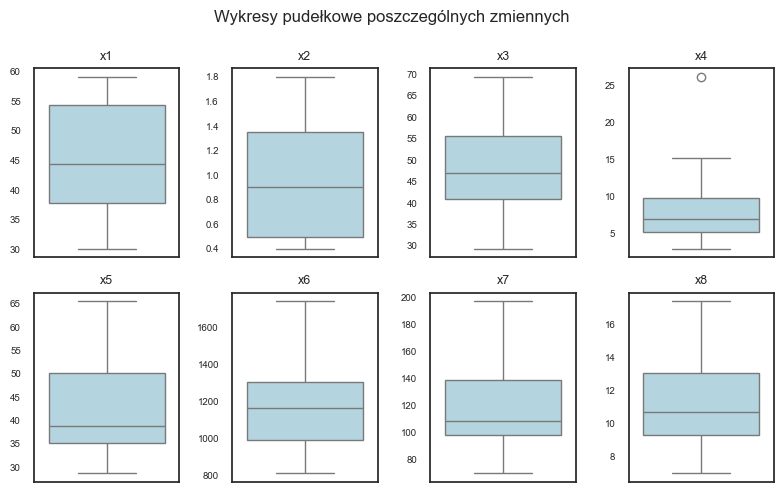

,liczba_outlierów,regiony_wystepowania_outlierow
x1,0,[]
x2,0,[]
x3,0,[]
x4,1,[Małopolskie]
x5,0,[]
x6,0,[]
x7,0,[]
x8,0,[]


In [6]:
eda.box_plots(df, all_vars)
eda.outliers(df, all_vars)

Wykresy pokazują, że większość zmiennych jest prawostronnie skośna; udział gruntów ugorowanych($x_2$), liczba pracujących w rolnictwie($x_4$), nakłady inwestycyjne($x_5$), wartość brutto środków trwałych($x_6$), zużycie nawozów($x_7$) czy globalna produkcja($x_8$). Największą skośnością odznacza się zmienna $x_4$, zmienne $x_5$,$x_7$ są umiarkowanie skośne, a pozostałe zmienne są tylko lekko skośne(mediana leży bliżej środka pudełka).

Udział użytków rolnych w powierzchni województwa i udział gruntów zmeliorowanych ($x_1$,$x_3$) są w przybliżeniu symetryczne.

Zmienna $x_4$ jest jedyną zmienną z wartością odstającą - wartość odstająca występuje w województwie małopolskim - ten region odznacza się bardzo dużą liczbą osób pracujących w rolnictwie na tle pozostałych województw.

Zmienna $x_6$ dla województwa śląskiego ostatecznie nie okazała się wartością odstającą.

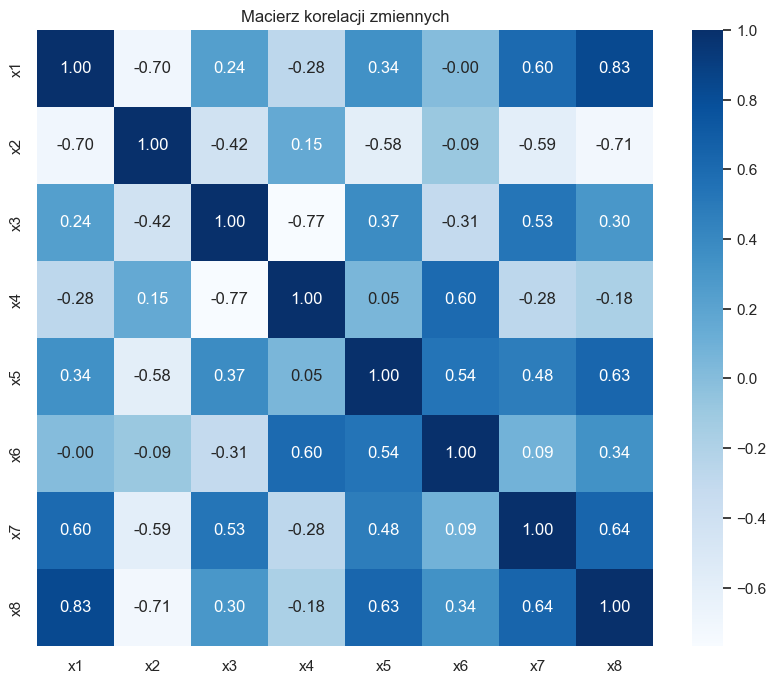

In [7]:
eda.correlation_matrix_heatmap(df, all_vars)

Ostatnim elementem wstępnej EDA jest analiza korelacji pomiędzy poszczególnymi zmiennymi.

Najważniejsza zależność:
- największą korelacją (dodatnią) na poziomie (r=0,83) odznacza się para [x1,x8] - udział użytków rolnych i globalna produkcja - w publikacji autorka odrzucała wszystkie zmienne, których współczynnika korelacji przekroczyła próg 0,8. Jednakże dla tego badania, w celu porównania wyników z badaniem z publikacji, pozostawione zostaną wszystkie zmienne.

Inne istotne korelacje:

Dodatnie:
- [x7,x8] (r=0,64) – zużycie nawozów a globalna produkcja: intensywniejsze nawożenie idzie w parze z wyższą produkcją
- [x5,x8] (r=0,63) – nakłady inwestycyjne a globalna produkcja: więcej inwestuje się tam, gdzie produkcja jest wyższa.
- [x1,x7] (r=0,60) – udział użytków rolnych a zużycie nawozów: w województwach typowo rolniczych rolnictwo jest bardziej intensywne.
- [x4,x6] (r=0,60) – pracujący w rolnictwie a wartość środków trwałych: w regionach z rozdrobnionymi gospodarstwami każde z nich ma własny majątek, więc na 100 ha przypada go więcej.

Ujemne:
- [x3,x4] (r=−0,77) – udział zmeliorowanych użytków rolnych a pracujący w rolnictwie: duże gospodarstwa na północy i zachodzie kraju mają rozbudowane melioracje i niskie zatrudnienie, a rozdrobnione na południowym wschodzie – odwrotnie.
- [x2,x8] (r=−0,71) – udział ugorów a globalna produkcja: im więcej ziemi leży odłogiem, tym niższa produkcja.
- [x1,x2] (r=−0,70) – udział użytków rolnych a udział ugorów: w województwach typowo rolniczych ziemia jest wykorzystywana pełniej.

## Porządkowanie liniowe

Ranking województw ze względu na potencjał rolnictwa dla 2023 roku sporządzono wybranymi metodami, oznaczając je następująco:

* metoda bezwzorcowa, normalizacja cech poprzez standaryzację (R1),
* metoda bezwzorcowa, normalizacja cech metodą unitaryzacji zerowanej (R2),
* wskaźnik rozwoju Hellwiga, normalizacja cech poprzez standaryzację (R5),
* metoda TOPSIS, normalizacja cech poprzez standaryzację (R6).

In [8]:
import linear_ordering
z_std, z_unit = linear_ordering.normalize_data(df, stimulants, all_vars)

df_res = linear_ordering.calculate_synthetic_variables(df, z_std, z_unit)

df_u, df_u_bar, best_ranking_code = linear_ordering.evaluate_similarity(df_res, len(df))

df_res["Klasa"] = linear_ordering.assign_classes(df_res[f"q_{best_ranking_code}"])

ranks_historical = {
    "Opolskie": 1,
    "Śląskie": 2,
    "Wielkopolskie": 3,
    "Kujawsko-pomorskie": 4,
    "Łódzkie": 5,
    "Dolnośląskie": 6,
    "Pomorskie": 7,
    "Mazowieckie": 8,
    "Lubelskie": 9,
    "Świętokrzyskie": 10,
    "Małopolskie": 11,
    "Zachodniopomorskie": 12,
    "Podlaskie": 13,
    "Warmińsko-mazurskie": 14,
    "Lubuskie": 15,
    "Podkarpackie": 16,
}

df_comp = linear_ordering.compare_with_historical(df_res, best_ranking_code, ranks_historical)

df_res[["Województwo", "R1", "R2", "R5", "R6", "Klasa"]]

,Województwo,R1,R2,R5,R6,Klasa
0,Dolnośląskie,4,4,4,4,Klasa II (wysoki)
1,Kujawsko-pomorskie,3,3,3,3,Klasa I (bardzo wysoki)
2,Lubelskie,11,10,10,11,Klasa III (średni)
3,Lubuskie,15,15,16,14,Klasa V (bardzo niski)
4,Łódzkie,7,7,5,7,Klasa III (średni)
5,Małopolskie,13,12,14,13,Klasa V (bardzo niski)
6,Mazowieckie,6,6,6,6,Klasa III (średni)
7,Opolskie,1,1,1,1,Klasa I (bardzo wysoki)
8,Podkarpackie,16,16,15,16,Klasa V (bardzo niski)
9,Podlaskie,5,5,7,5,Klasa II (wysoki)


Tabela przedstawiająca pozycje poszczególnych województw ze względu na potencjał rolnictwa potwierdza spostrzeżenie wskazane w publikacji o możliwości wystąpienia różnic w pozycjach w rankingach uzyskanych różnymi metodami oraz konieczności stosowania miary określonej formułą pozwalającej wybrać wynik najbardziej podobny do pozostałych. Do wyróżnienia klas wykorzystano średnią i odchylenie standardowe zmiennej syntetycznej w następujący sposób:

* klasa I (bardzo wysoki poziom badanego zjawiska): $q_i \ge \bar{q} + 0,8416 \cdot s_q$
* klasa II (wysoki poziom): $\bar{q} + 0,8416 \cdot s_q > q_i \ge \bar{q} + 0,2533 \cdot s_q$
* klasa III (średni poziom): $\bar{q} + 0,2533 \cdot s_q > q_i \ge \bar{q} - 0,2533 \cdot s_q$
* klasa IV (niski poziom): $\bar{q} - 0,2533 \cdot s_q > q_i \ge \bar{q} - 0,8416 \cdot s_q$
* klasa V (bardzo niski poziom): $\bar{q} - 0,8416 \cdot s_q > q_i$

Do klasy I zakwalifikowały się województwa: Opolskie, Wielkopolskie i Kujawsko-Pomorskie. Są to regiony charakteryzujące się najwyższym natężeniem cech stymulujących, takich jak wysokie nakłady inwestycyjne i wysoka produkcja globalna. Województwa te zajmują miejsca 1-3 we wszystkich badanych metodach porządkowania, co potwierdza ich wysoki potencjał rolniczy.

W klasie II znalazły się województwa Dolnośląskie oraz Podlaskie. Mają one poziom potencjału rolniczego powyżej średniej krajowej. Posiadają one korzystną strukturę zmiennych diagnostycznych, ale ustępują województwom w I klasie ze względu na nieznacznie gorsze wyniki w niektórych obszarach.

Klasa III jest najliczniejszą grupą, obejmującą 6 województw: Mazowieckie, Łódzkie, Pomorskie, Warmińsko-mazurskie, Śląskie oraz Lubelskie. Województwa te charakteryzują się przeciętnym poziomem potencjału rolniczego. Wartości ich miar syntetycznych oscylują wokół średniej arytmetycznej dla całego kraju, co sugeruje umiarkowane nasycenie czynnikami produkcji rolniczej.

Na podstawie analizy rozkładu zmiennej syntetycznej nie wyodrębniono żadnego województwa, które zakwalifikowałoby się do klasy IV (poziom niski).

Do klasy V zaliczono 5 województw: Zachodniopomorskie, Małopolskie, Świętokrzyskie, Lubuskie oraz Podkarpackie. Regiony te charakteryzują się zdecydowanie najniższymi wartościami miary syntetycznej we wszystkich analizowanych wariantach. Silnie oddziałują na nie zmienne o charakterze destymulant, przy jednoczesnym bardzo niskim udziale cech stymulujących (np. niska produkcja na 1 ha, niski udział użytków rolnych, czy w przypadku woj. podkarpackiego i małopolskiego – niekorzystna struktura obszarowa gospodarstw). Województwo Podkarpackie znajduje się na końcu zestawienia w 3 z 4 zastosowanych metod.

In [9]:
linear_ordering.display_similarity(df_u_bar)

,R1,R2,R6,R5
Lata,,,,
2014,0.967,0.966,0.965,0.957
2023,0.995,0.992,0.993,0.987


Otrzymane rankingi należy uznać za podobne o czym świaczą miary podobieństwa powyżej 0.9, tak samo jak było w badaniu opartym na danych z 2014 roku.

Jako ranking do dalszych interpretacji wybrano zestawienie R1, ponieważ wykazuje najwyższą średnią wartość korelacji Spearmana ze wszystkimi pozostałymi wariantami.

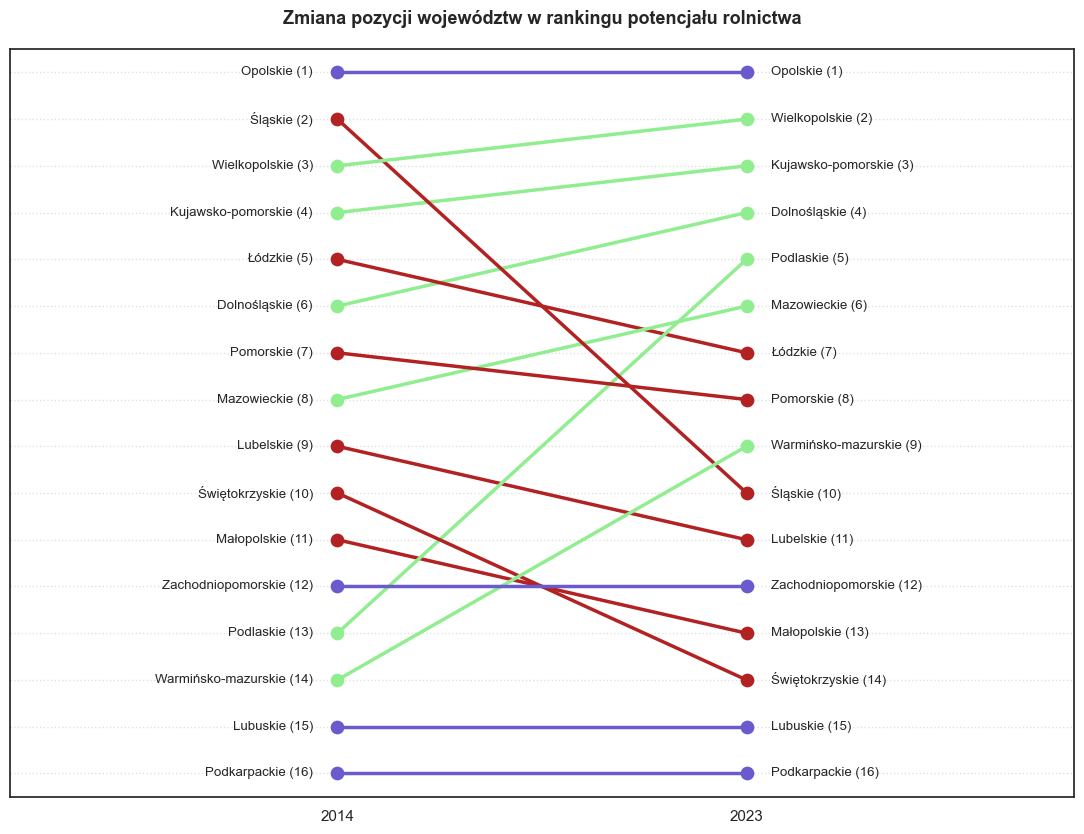

,Województwo,R_2023,R_2014,Zmiana_pozycji
0,Dolnośląskie,4,6,2
1,Kujawsko-pomorskie,3,4,1
2,Lubelskie,11,9,-2
3,Lubuskie,15,15,0
4,Łódzkie,7,5,-2
5,Małopolskie,13,11,-2
6,Mazowieckie,6,8,2
7,Opolskie,1,1,0
8,Podkarpackie,16,16,0
9,Podlaskie,5,13,8


In [10]:
linear_ordering.plot_ranking_comparison(df_comp)
df_comp

Porównanie wyników własnego badania z ustaleniami dla roku 2014 pozwala na ocenę stabilności oraz dynamiki potencjału rolniczego województw.  Na wykresie kolorem zielonym oznaczono awans, czerwonym spadek, a fioletowym brak zmiany.

Tylko cztery województwa utrzymały swoje pozycje z 2014 roku. Na szczycie rankingu bez zmian pozostało wyłącznie województwo opolskie (1. miejsce). W dolnej części zestawienia swoje pozycje zachowały województwa: zachodniopomorskie (12. miejsce), lubuskie (15. miejsce) oraz podkarpackie (16. miejsce).
Największą zmianę dodatnią odnotowało województwo podlaskie, przesuwając się z 13. na 5. pozycję (awans o 8 miejsc). Drugi co do wielkości wzrost dotyczy województwa warmińsko-mazurskiego, które zmieniło pozycję z 14. na 9. (awans o 5 miejsc). Poprawę odnotowały również: dolnośląskie (z 6. na 4.), mazowieckie (z 8. na 6.), kujawsko-pomorskie (z 4. na 3.) oraz wielkopolskie (z 3. na 2.). Największa zmiana ujemna dotyczy województwa śląskiego, które spadło z 2. miejsca w 2014 roku na 10. pozycję w 2023 roku (spadek o 8 miejsc). Województwo świętokrzyskie zanotowało spadek o 4 pozycje, przechodząc z 10. na 14. miejsce. Spadki o 2 pozycje dotyczyły województw: łódzkiego, lubelskiego i małopolskiego, a o 1 pozycję – województwa pomorskiego. Oznacza to, że w nowszym badaniu zmiany były dwukierunkowe: sześć województw awansowało, sześć spadło, a cztery utrzymały pozycję. Warto jednak mieć na uwadze, że rzeczywista kolejność województw w roku 2014 może być inna niż w publikacji.

## Analiza skupień

## Grupowanie hierarchiczne

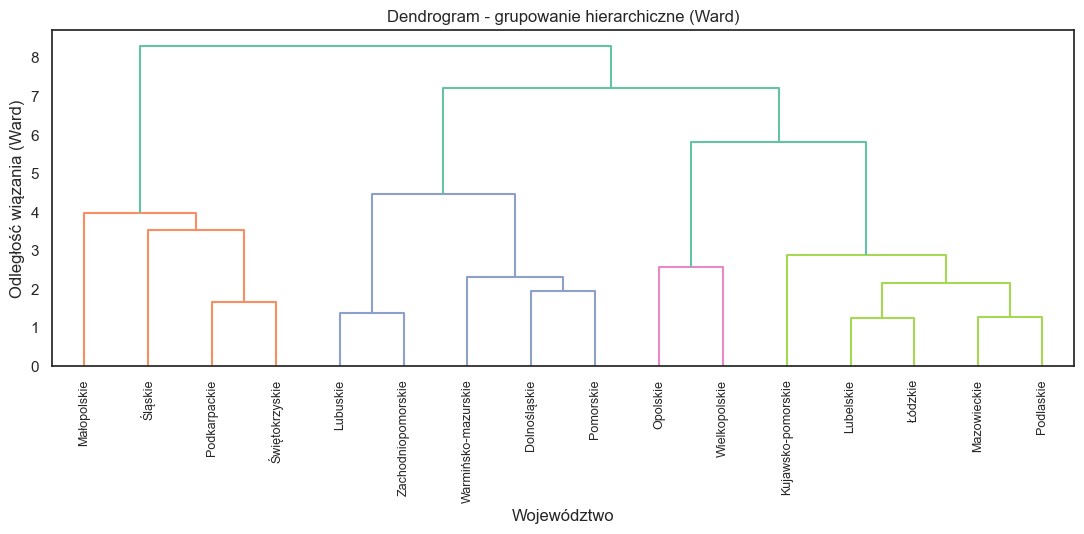

In [11]:
import clustering
x, names, df_indexed = clustering.prepare_clustering_data(df, z_std)
z = clustering.hierarchical_clustering(x)
clustering.plot_dendrogram(z, names)

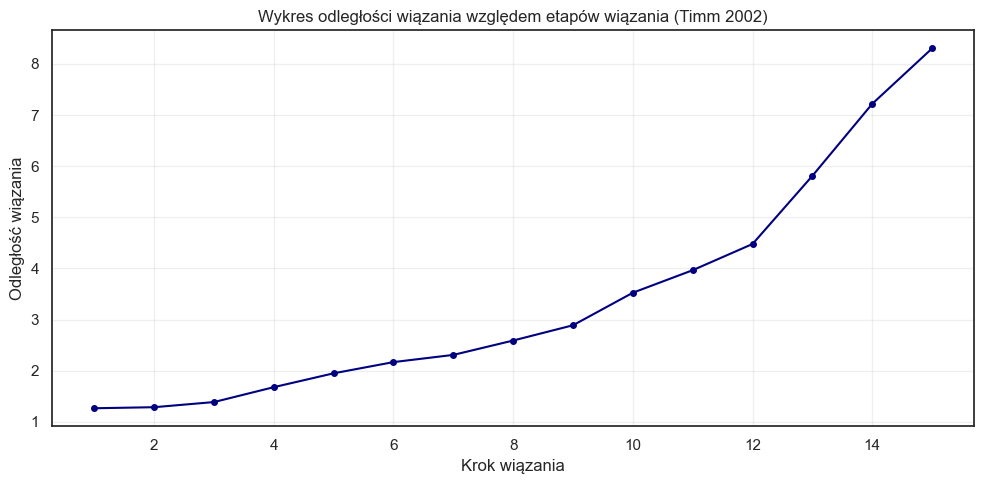

In [12]:
df_heights = clustering.plot_merge_heights(z)

Na wykresie przedstawiającym odległości wiązań widać, że największe przyrosty odległości występują przy przejściu z 4 do 3 skupień oraz z 3 do 2 skupień. Oba te przyrosty otaczają podział na 3 grupy. W przypadku przejścia z 4 do 5 skupień przyrost odległości jest znacznie mniejszy, co sugeruje, że podział na 4 grupy jest mniej stabilny.

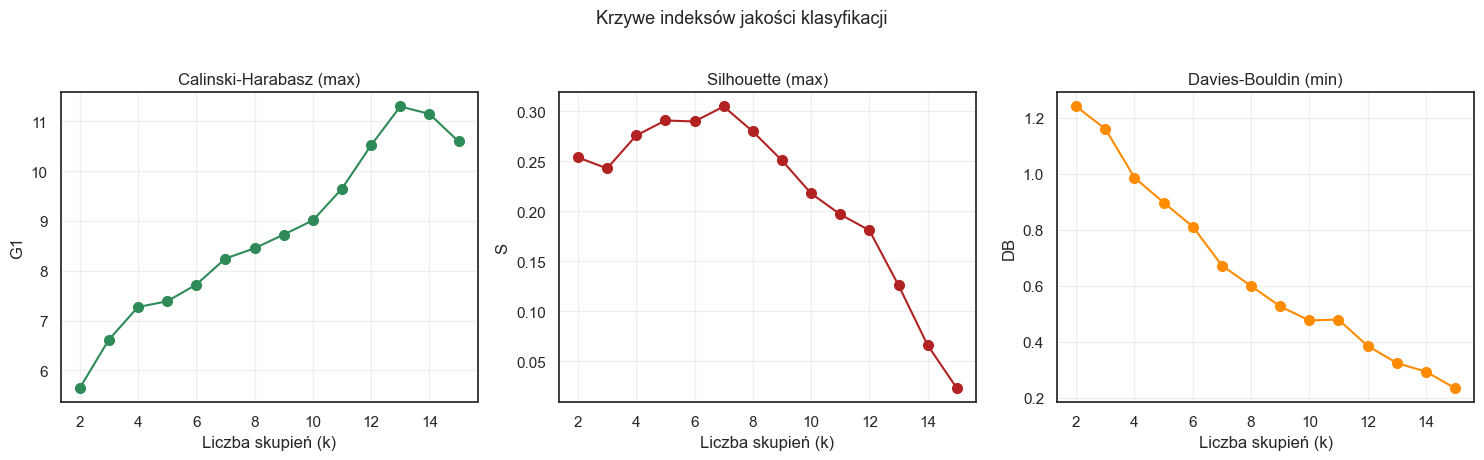

In [13]:
df_k = clustering.plot_k_hierarchical(z, x, k_range=range(2, 16))
clustering.plot_cluster_indices(df_k)

Indeks G1, który mierzy stosunek średniej wariancji międzygrupowej do średniej wariancji wewnątrzgrupowej (z uwzględnieniem stopni swobody), rośnie od k=2 i osiąga maksimum dla k=13. Indeks S, skupiający się na porównaniu średniej odległości obiektu od własnej grupy do średniej odległości od najbliższej innej grupy, osiąga lokalne minimum dla k=3 oraz maksimum dla k=7, co wskazuje, że przy podziale na 3 grupy granice klastrów są najbardziej rozmyte (województwa z różnych grup są do siebie bardzo zbliżone), a przy 7 grupach obiekty są blisko swoich sąsiadów i daleko od pozostałych obiektów. Indeks DB maleje wraz ze wzrostem k w całym przedziale (z minimalnym wzrostem przy przejściu z k=10 na k=11), mierzy on średni stosunek sumy rozproszeń wewnątrz dwóch najbliższych grup do odległości między ich centrami, więc im niższa jest jego wartość, tym grupy są bardziej zwarte i lepiej od siebie oddzielone. Najlepszy pod tym względem jest podział na 15 grup.

Można więc wywnioskować, że w badanych danych nie występuje silna struktura hierarchiczna. Województwa nie tworzą silnie zróżnicowanych grup. Podziały na 7, 10 czy 11 grup są matematycznie optymalne (obiekty w danej grupie byłyby do siebie podobne), ale z punktu widzenia analizy regionalnej prowadzą do powstania małych grup.

Biorąc pod uwagę dendrogram oraz analizę odległości skupień należy rozważyć podział na 3 lub 4 grupy. Dla k=4 indeks S jest wyższy (k=3 jest lokalnym minimum), indeks G1 jest wyższy, a DB niższy, co sugeruje, że k=4 jest bardziej uzasadnione. Z kolei wokół k=3 na wykresie odległości występują największe skoki odległości, dla tego podziału liczba województw w poszczególnych grupach jest bardziej zbilansowana (7, 5, 4).

W związku z tym, że podział na 4 grupy pozwala na wyodrębnienie dwóch województw o najwyższym potencjale rolniczym, do dalszej analizy przyjęto podział na 4 grupy.

In [14]:
from scipy.cluster.hierarchy import cut_tree
labels_ward = cut_tree(z, n_clusters=[4]).ravel()
clustering.list_group_members(names, labels_ward)

{0: ['Dolnośląskie',
  'Lubuskie',
  'Pomorskie',
  'Warmińsko-mazurskie',
  'Zachodniopomorskie'],
 1: ['Kujawsko-pomorskie', 'Lubelskie', 'Mazowieckie', 'Podlaskie', 'Łódzkie'],
 2: ['Małopolskie', 'Podkarpackie', 'Śląskie', 'Świętokrzyskie'],
 3: ['Opolskie', 'Wielkopolskie']}

In [15]:
clustering.profile_groups(df, labels_ward, all_vars)

Klaster,0,1,2,3,Ogółem
Zmienna,,,,,
x1,39.56 (5.59),55.15 (1.7),34.4 (4.86),56.63 (3.48),45.28 (10.33)
x2,1.04 (0.5),0.74 (0.28),1.35 (0.42),0.4 (0.0),0.94 (0.47)
x3,55.6 (4.42),42.96 (3.18),36.25 (7.29),63.05 (8.98),47.74 (10.89)
x4,4.13 (0.98),8.08 (1.59),15.96 (7.2),6.22 (0.98),8.58 (5.77)
x5,39.06 (11.62),39.36 (5.39),42.26 (10.01),65.13 (0.58),43.21 (11.78)
x6,917.27 (93.19),1169.63 (122.49),1435.23 (258.41),1366.6 (93.88),1181.79 (255.57)
x7,108.8 (30.1),127.98 (29.01),100.08 (11.1),168.1 (41.15),120.02 (32.88)
x8,9.33 (1.64),12.89 (1.52),9.15 (1.53),15.59 (2.59),11.18 (2.84)


   - $x_1$: udział użytków rolnych w powierzchni województwa
   - $x_2$: udział gruntów ugorowanych
   - $x_3$: udział zmeliorowanych użytków rolnych
   - $x_4$: pracujący w rolnictwie na 100 ha użytków rolnych
   - $x_5$: nakłady inwestycyjne w rolnictwie i łowiectwie na 100 ha użytków rolnych w tys. zł
   - $x_6$: wartość brutto środków trwałych w rolnictwie i łowiectwie na 100 ha użytków rolnych w tys. zł
   - $x_7$: zużycie nawozów mineralnych lub chemicznych na 1 ha użytków rolnych w kg
   - $x_8$: globalna produkcja rolnicza na 1 ha użytków rolnych w tys. zł

**Klaster 0: Województwa Dolnośląskie, Lubuskie, Pomorskie, Warmińsko-mazurskie, Zachodniopomorskie**

Grupa charakteryzuje się najniższym poziomem zatrudnienia w rolnictwie ($x_4$ = 4,13 os./100 ha, przy średniej krajowej 8,58), co wskazuje na dominację gospodarstw o dużej powierzchni. Jednocześnie regiony te odznaczają się najniższymi nakładami inwestycyjnymi ($x_5$ = 39,06 tys. zł) oraz najniższą wartością brutto środków trwałych ($x_6$ = 917,27 tys. zł). Mimo relatywnie wysokiego udziału gruntów zmeliorowanych ($x_3$ = 55,60%), globalna produkcja rolnicza ($x_8$ = 9,33 tys. zł/ha) jest tu prawie najniższa w całym zestawieniu. Wskazuje to na duże gospodarstwa, charakteryzujące się niedoborem kapitału i niską wydajnością.

**Klaster 1: Województwa Kujawsko-pomorskie, Lubelskie, Mazowieckie, Podlaskie, Łódzkie**

Grupa o wysokim potencjale rolniczym, charakteryzująca się dużym udziałem użytków rolnych($x_1$ = 55,15%) oraz ponadprzeciętną produkcją($x_8$ = 12,89 tys. zł/ha) i zużyciem nawozów($x_7$ = 127,98 kg/ha). W stosunku do klastra 3 uwidacznia się jednak niedobór nakładów inwestycyjnych ($x_5$ = 39,36 tys. zł, przy średniej krajowej 43,21 tys. zł) oraz niższy udział gruntów zmeliorowanych ($x_3$ = 42,96%). Niskie wartości odchyleń standardowych wewnątrz grupy świadczą o jej wysokiej homogeniczności. Są to silne, tradycyjne regiony rolnicze o ugruntowanej strukturze, wymagające jednak intensyfikacji inwestycji w celu pełnego wykorzystania potencjału.

**Klaster 2: Województwa Małopolskie, Podkarpackie, Śląskie, Świętokrzyskie**

Grupa o najbardziej niekorzystnej strukturze agrarnej. Odnotowuje się tu najwyższy poziom zatrudnienia w rolnictwie ($x_4$ = 15,96 os./100 ha), co przy jednoczesnym najniższym udziale użytków rolnych ($x_1$ = 34,40%) oraz najniższym zużyciu nawozów ($x_7$= 100,08 kg/ha) i produkcji globalnej ($x_8$ = 9,15 tys. zł/ha) wskazuje na wysokie rozdrobnienie gospodarstw oraz niską towarowość produkcji.

**Klaster 3: Województwa Opolskie, Wielkopolskie**

Grupa liderów, przewyższająca średnią krajową w niemal wszystkich zmiennych diagnostycznych o charakterze stymulant. Województwa te legitymują się najwyższym udziałem użytków rolnych ($x_1$ = 56,63%) oraz gruntów zmeliorowanych ($x_3$ = 63,05%), przy jednocześnie najniższym udziale gruntów ugorowanych ($x_2$ = 0,40%). Charakteryzują się najwyższą intensywnością produkcji ($x_8$ = 15,59 tys. zł/ha, $x_7$ = 168,10 kg/ha) oraz najwyższymi nakładami inwestycyjnymi ($x_5$ = 65,13 tys. zł). Bardzo niskie odchylenia standardowe (np. 0,00 dla $x_2$) wskazują na podobieństwo obu województw pod względem analizowanych cech.

## Grupowanie podziałowe

W celu wyznaczenia optymalnego k za pomocą grupowania podziałowego, wykorzystane zostaną wskaźniki jakości policzone dla metody k-means oraz wykres inercji względem liczby skupień odczytywany metodą łokcia.

Inercja jest to wielkość, która mierzy zwartość skupień - im mniejsza wartość, tym obiekty są bliżej środka swojej grupy. Naturalnie wraz ze wzrostem liczby skupień, wartość ta będzie malała.

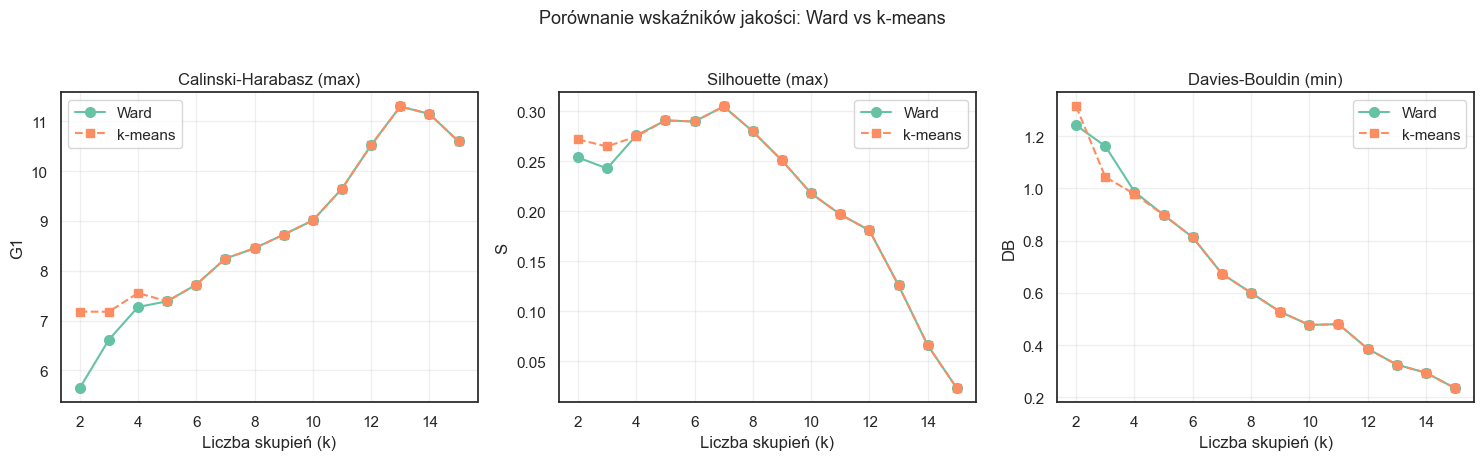

In [16]:
df_k_means = clustering.kmeans_indices(x, k_range=range(2, 16))

clustering.plot_indices_comparison(df_k, df_k_means)

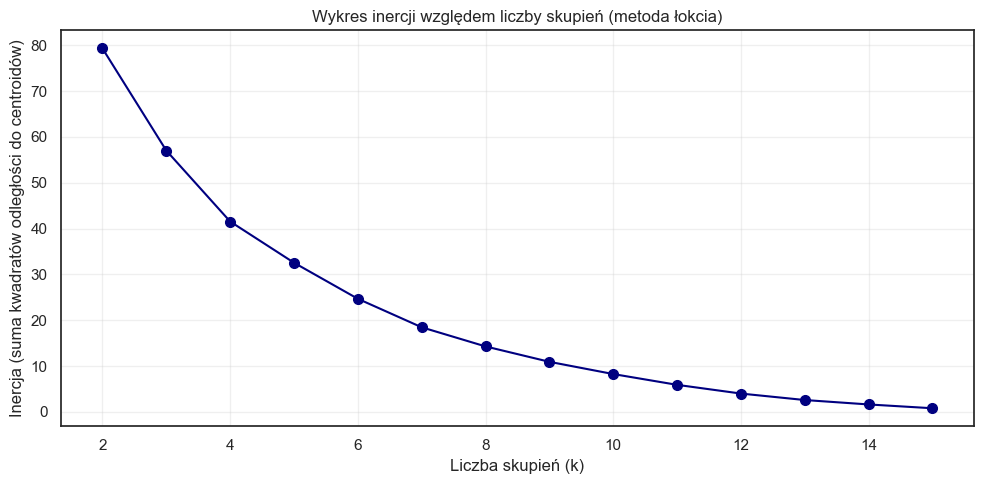

In [17]:
clustering.plot_elbow(df_k_means)

Wskaźniki zostały policzone w tym samym zakresie jak dla grupowania hierarchicznego (k=2-15). Znaleziono ciekawą zależność; dla k >= 5 wykresy w obu metodach pokrywają się - dlatego w tym przedziale wnioski będą identyczne jak w grupowaniu hierarchicznym.

Różnice w wartościach wskaźników widoczne są w przedziale k=2-4. Indeksy G1 i S osiągają wyższe wartości w metodzie k-means niż w metodzie Warda (w metodzie k-means można przenosić województwa pomiędzy skupieniami). Istotnym spostrzeżeniem jest to, że w metodzie k-means dla indeksu G1 w k=4 występuje maksimum lokalne, co sugeruje podział na 4 skupienia, tak jak w metodzie Warda.

Podział na 4 skupienia jest również potwierdzony przez metodę łokcia (silny spadek z 2-3 i nieco słabszy z 3-4, gdzie w kolejnych grupach wykres powoli się wypłaszcza).

Warto jednak zwrócić uwagę na niskie wartości indeksu S, co może sugerować, że skupienia nie są od siebie wyraźnie odseparowane.

W dalszej analizie ostatecznie przyjęto k=4 czyli podział na cztery skupienia, ze względu na wyżej wymienione zależności, ale również, aby móc dokładnie porównać metodę k-means z metodą Warda.

In [18]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, n_init=100, random_state=42)
labels_km = kmeans.fit_predict(x)
clustering.list_group_members(names, labels_km)

{0: ['Dolnośląskie',
  'Kujawsko-pomorskie',
  'Lubelskie',
  'Mazowieckie',
  'Podlaskie',
  'Łódzkie'],
 1: ['Lubuskie', 'Pomorskie', 'Warmińsko-mazurskie', 'Zachodniopomorskie'],
 2: ['Małopolskie', 'Podkarpackie', 'Śląskie', 'Świętokrzyskie'],
 3: ['Opolskie', 'Wielkopolskie']}

In [19]:
clustering.profile_groups(df, labels_km, all_vars)

Klaster,0,1,2,3,Ogółem
Zmienna,,,,,
x1,53.54 (4.24),38.09 (5.21),34.4 (4.86),56.63 (3.48),45.28 (10.33)
x2,0.72 (0.26),1.15 (0.51),1.35 (0.42),0.4 (0.0),0.94 (0.47)
x3,45.0 (5.75),55.7 (5.1),36.25 (7.29),63.05 (8.98),47.74 (10.89)
x4,7.51 (1.99),4.0 (1.08),15.96 (7.2),6.22 (0.98),8.58 (5.77)
x5,42.53 (9.14),34.23 (4.94),42.26 (10.01),65.13 (0.58),43.21 (11.78)
x6,1139.88 (131.57),898.79 (96.45),1435.23 (258.41),1366.6 (93.88),1181.79 (255.57)
x7,129.88 (26.37),101.15 (28.6),100.08 (11.1),168.1 (41.15),120.02 (32.88)
x8,12.52 (1.62),8.98 (1.66),9.15 (1.53),15.59 (2.59),11.18 (2.84)


Warto w tym momencie przypomnieć, że zmienne$x_1$,$x_3$,$x_5$,$x_6$,$x_7$,$x_8$ to stymulanty, a zmienne$x_2$,$x_4$ to destymulanty i w tym kontekście będą analizowane ich wartości w klastrach.

Na podstawie metody k-means wyodrębniono cztery klastry województw pod względem potencjału rolnictwa:
- Klaster 3 (woj. Opolskie i woj. Wielkopolskie) - Skupienie z największym potencjałem na rozwój rolnictwa - te dwa regiony odznaczają się najwyższą wartością w prawie wszystkich stymulantach (użytki rolne, melioracja, nakłady inwestycyjne, nawozy, produkcja), zachowując przy tym niskie albo najniższe (ugory) wartości destymulant.
- Klaster 0 (woj. Dolnośląskie, Kujawsko-Pomorskie, Lubelskie, Mazowieckie, Podlaskie, Łódzkie) - wartości zmiennych zbliżone do średnich wartości dla całego kraju; duży udział użytków rolnych, zużycie nawozów czy produkcja.
- Klaster 1 (woj. Lubuskie, Pomorskie, Warmińsko-Mazurskie, Zachodniopomorskie) - skupienie regionów z wartościami stymulant niższymi niż średnia krajowa (wyjątkiem melioracje (x3)). Charakteryzuje go najniższa liczba pracujących na 100 ha użytków rolnych, która dla rozwoju rolnictwa jest korzystna.
- Klaster 2 (woj. Małopolskie, Podkarpackie, Śląskie, Świętokrzyskie) - skupienie z wartością odstającą (woj. Małopolskie) - największe wartości destymulant, przy niskich lub najniższych wartościach stymulant (wyjątkiem jest największa wartość środków trwałych (x6) oraz przeciętne nakłady inwestycyjne(x5)).

Porównując klastry z grupowania podziałowego z tymi z grupowania hierarchicznego można zauważyć, że są niemal identyczne jedyną różnicą jest obecność województwa Dolnośląskiego w klastrze z województwami: Kujawsko-Pomorskie, Lubelskie, Mazowieckie, Podlaskie, Łódzkie, gdy w grupowaniu hierarchicznym występowało ono w klastrze z woj. Lubuskim, Pomorskim, Warmińsko-Mazurskim i Zachodniopomorskim. Numery klastrów w obu metodach są niezależne ze sobą.

# Podsumowanie

Głównym celem projektu była ocena potencjału rolnictwa w poszczególnych województwach RP na podstawie danych z Rocznika Statystycznego Rolnictwa GUSu 2025. Dodatkowo wyniki zostały porównane z wynikami badań J. Kisielińskiej za rok 2014.

**Najważniejsze wnioski:**
- EDA wykazała, że wraz z upływem czasu rolnictwo w Polsce zostało zintensyfikowane i skoncentrowane - zmniejszenie powierzchni gruntów ugorowych, zmniejszenie ilości ludzi pracujących w rolnictwie z jednakowym zwiększeniem użycia nawozów. W trakcie EDA odkryto też nieścisłości w danych z publikacji z danymi z GUSu, z których autorka publikacji korzystała - błędy zostały naprawione w celu rzetelnego porównania statystyk opisowych.

- Porządkowanie liniowe 2 metodami bezwzorcowymi 2 wzorcowymi ukazało bardzo zbliżone do siebie rankingi. Do województw, które nie zmieniły swoich pozycji w upływie czasu należą Opolskie (1), Zachodniopomorskie(12), Lubuskie(15), Podkarpackie(16). Największy wzrost potencjału rolnictwa w rankingu zanotowało województwo Podlaskie (13 -> 5), a największy spadek potencjału rolnictwa zanotowało województwo Śląskie (2 -> 10). Na rok 2023 u góry rankingu województw z najwyższym potencjałem rolnictwa znajdują się: Opolskie(1), Wielkopolskie(2), Kujawsko-Pomorskie(3), a na dole rankingu znajdują się : Świętokrzyskie(14), Lubuskie(15), Podkarpackie(16).

- Przeprowadzone zostały 2 typy analizy skupień (hierarchiczne - metodą Warda i podziałowe - metodą K-means). Wyodrębniła ona 4 grupy skupień rolnictwa w Polsce. Metoda Warda i k-means były bardzo spójne, gdyż ich klastry praktycznie całkowicie się pokrywały, różniąc się jedynie jednym województwem. Wyniki analizy skupień pokrywały się z wynikami porządkowania liniowego (liderami opolskie i wielkopolskie), do gorzej radzących sobie województw(świętokrzyskie, podkarpackie). Ukazuje to spójność obu analiz.



